# 01 · Exploratory data analysis

**Team SPELUNCA · ExxonMobil DataWorks Challenge 2026**

## Purpose
Before building any model, we look at every input file to answer one question: *what does the data let us do,
and what does it force us to do?* Each section ends with **Findings** (written from the data when the notebook
runs) and an **Implication** for the method in `02_pipeline.ipynb`.

## Research context
**Main research question.** Can a machine-learning proxy, trained on 100 simulated reservoir cases, identify the
parameter values that reproduce the field's observed 1998–2008 production, and use them to forecast cumulative oil,
gas and water to 2028 with an honest uncertainty range?

| EDA section | Question it answers | Feeds |
|---|---|---|
| 1. Files and sheets | Which data is actually available? | All steps |
| 2. Uncertainty parameters | What design space do the 100 cases cover, and are the inputs independent? | SRQ2, SRQ3, SRQ4 |
| 3. Observed production | How does the real field behave (plateau, decline, water)? | SRQ2, SRQ5 |
| 4. Simulated curves | What form are the simulations in, and how far do they reach? | SRQ1, SRQ5 |
| 5. Date convention | Are simulated and observed volumes stamped the same way? | SRQ1 |
| 6. Gas–oil ratio | Is the gas all solution gas? | SRQ5 |
| 7. Drivers | Which parameter controls the 1998–2008 production? | SRQ2, SRQ3, SRQ4 |
| 8. Cases vs observed | Does the field lie inside the range of the 100 simulations? | SRQ2 |
| 9. Grid files | Do the grid files hold information beyond the 4 parameters? Where are the oil, aquifer and permeability region? | SRQ4, SRQ3 |
| 10. Summary | What the EDA decides for the method | `02_pipeline` |

## Data
| File | Content | Used here |
|---|---|---|
| `01 Introduction.xlsx` | Uncertainty values of the 4 parameters for Cases 1–100 | §2, §7, §9 |
| `02 Field Production.xlsx` | Observed field rates (quarterly) and simulated cumulative / rate curves for Cases 1–100 | §1, §3–§8 |
| `03`–`08` case workbooks | Cell-by-cell grid properties, one sheet per case | §9 (optional) |

Units: oil and water in stock-tank barrels (STB), gas in thousand standard cubic feet (MSCF), rates per day.

> **Read-only.** Nothing in this notebook changes the data or writes outputs.
>
> **Confidential.** The outputs below contain competition data, so clear all outputs before committing (a test
> checks this).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import load_config
from src.report import millions, pct, sci, show_md, show_table, verdict

pd.set_option("display.max_columns", 50)
cfg = load_config(ROOT / "config.yaml", root=ROOT)   # data folder: DWC26_DATA_DIR in .env, else data/raw
print("Data folder:", cfg["paths"]["raw"])

Data folder: C:\SpeluncaDWC26trst\data\raw


## 1. Files and sheets

**Why.** The method can only use what exists. The Kick Off deck mentions pressure, so we check whether a pressure
sheet is provided; we also confirm which sheets the pipeline reads.

In [2]:
from src import io_load

sheets = io_load.list_field_sheets(cfg)
curve_sheets = list(cfg["sheets"]["curves"].values())
inventory = pd.DataFrame({"sheet": sheets,
                          "read by the pipeline": [s == cfg["sheets"]["field"] or s in curve_sheets for s in sheets]})
show_table(inventory.rename(columns={"sheet": "Sheet", "read by the pipeline": "Read by the pipeline"}),
           title="Sheets in 02 Field Production.xlsx", highlight=inventory["read by the pipeline"].tolist())

Sheet,Read by the pipeline
Plots,No
Field Production,Yes
Gas production cumulative,Yes
Gas production rate,No
Oil production cumulative,Yes
Oil production rate,No
Water production cumulative,Yes
Water production rate,No


In [3]:
has_pressure = any("pressure" in s.lower() for s in sheets)
unused = inventory.loc[~inventory["read by the pipeline"], "sheet"].tolist()
show_md(f"""**Findings**
- `02 Field Production.xlsx` has **{len(sheets)} sheets**: {", ".join(f"`{s}`" for s in sheets)}.
- A pressure sheet is **{"present" if has_pressure else "not provided"}**.
- Not read by the pipeline: {", ".join(f"`{s}`" for s in unused) or "none"}. Rate sheets are not needed because
  rates are derived exactly from the cumulative curves (formula F21); `Plots` holds charts only.

**Implication.** {"Pressure can be used as a matching target." if has_pressure else
"History matching can use production volumes only (oil, gas, water). Reservoir pressure cannot be matched, so "
"parameters that act mainly through pressure support (aquifer size, fault sealing) are likely to be less well "
"constrained by the history. This is tested in §7 and in SRQ2."}""")

**Findings**
- `02 Field Production.xlsx` has **8 sheets**: `Plots`, `Field Production`, `Gas production cumulative`, `Gas production rate`, `Oil production cumulative`, `Oil production rate`, `Water production cumulative`, `Water production rate`.
- A pressure sheet is **not provided**.
- Not read by the pipeline: `Plots`, `Gas production rate`, `Oil production rate`, `Water production rate`. Rate sheets are not needed because
  rates are derived exactly from the cumulative curves (formula F21); `Plots` holds charts only.

**Implication.** History matching can use production volumes only (oil, gas, water). Reservoir pressure cannot be matched, so parameters that act mainly through pressure support (aquifer size, fault sealing) are likely to be less well constrained by the history. This is tested in §7 and in SRQ2.

## 2. Uncertainty parameters: the design space

**Why.** The four parameters are the inputs of the proxy (SRQ4) and the unknowns of history matching (SRQ2).
We check their ranges (scaling), whether they were varied independently (needed for a clean sensitivity analysis,
SRQ3) and whether the validation and test cases lie inside the range of the training cases (a proxy should not be
judged on extrapolation).

In [4]:
from src.utils import split_of

params = io_load.load_uncertainty(cfg)
names = list(params.columns)
split = pd.Series([split_of(c, cfg["split"]) for c in params.index], index=params.index, name="split")
desc = params.describe().T.rename(columns={"count": "Cases", "mean": "Mean", "std": "Std", "min": "Min",
                                           "25%": "P25", "50%": "Median", "75%": "P75", "max": "Max"})
show_table(desc.rename_axis("Parameter"), title="The 4 uncertainty parameters over the 100 cases",
           formats={c: ("{:.0f}" if c == "Cases" else "{:,.4f}") for c in desc.columns})

corr = params.corr(method="spearman")
show_table(corr.rename_axis("Parameter"), title="Spearman correlation between the inputs (ρ)", formats="{:+.3f}",
           note="Values near 0 mean the parameters were varied independently of each other.")

ranges = params.join(split).groupby("split")[names].agg(["min", "max"]).T.unstack()
ranges = ranges.reindex(columns=["train", "validation", "test"], level=0)
show_table(ranges.rename(columns=str.capitalize, level=0).rename(columns=str.capitalize, level=1)
           .rename_axis("Parameter"), title="Range of each parameter by split", formats="{:,.4f}")

Parameter,Cases,Mean,Std,Min,P25,Median,P75,Max
Fault Transmissibility,100,0.0996,0.0301,0.0501,0.0750,0.0986,0.1267,0.1500
Porosity Multiplier,100,1.1485,0.2041,0.8012,0.9773,1.1448,1.3483,1.4940
Permeability Multiplier,100,5.1998,2.7267,0.5205,2.7782,5.3092,7.5346,9.7845
Aquifer Pore Volume,100,125.1659,42.3698,53.9529,89.8479,125.7718,159.6597,199.8352


Parameter,Fault Transmissibility,Porosity Multiplier,Permeability Multiplier,Aquifer Pore Volume
Fault Transmissibility,+1.000,+0.143,-0.049,-0.004
Porosity Multiplier,+0.143,+1.000,-0.013,-0.073
Permeability Multiplier,-0.049,-0.013,+1.000,+0.172
Aquifer Pore Volume,-0.004,-0.073,+0.172,+1.000


Parameter,Train · Min,Train · Max,Validation · Min,Validation · Max,Test · Min,Test · Max
Fault Transmissibility,0.0508,0.1500,0.0501,0.1386,0.0519,0.1499
Porosity Multiplier,0.8012,1.4940,0.8365,1.4724,0.8098,1.4791
Permeability Multiplier,0.5375,9.5020,0.7716,9.7845,0.5205,9.6547
Aquifer Pore Volume,53.9529,199.8352,56.2642,198.8256,57.3992,175.5205


In [5]:
off = corr.where(~np.eye(len(names), dtype=bool)).abs().stack()
pair = off.idxmax()
ratio = params.max() / params.min()
tr = params[split == "train"]
def beyond(s):
    """Parameters where split s leaves the training range, with the overshoot as % of the training range."""
    out = []
    for n in names:
        v, lo, hi = params.loc[split == s, n], tr[n].min(), tr[n].max()
        over = max(lo - v.min(), v.max() - hi, 0.0) / (hi - lo)
        if over > 0:
            out.append(f"{n} (by {pct(over)} of the training range)")
    return out


outside = {s: beyond(s) for s in ("validation", "test")}
counts = split.value_counts()
show_md(f"""**Findings**
- {len(params)} cases: **{counts.get('train', 0)} train**, **{counts.get('validation', 0)} validation**,
  **{counts.get('test', 0)} test** (organisers' split).
- Max / min ratio of each parameter: {", ".join(f"{n} {ratio[n]:.1f}×" for n in names)}.
- Largest correlation between two inputs: |ρ| = **{off.max():.3f}** ({pair[0]} and {pair[1]}), so the inputs were
  {"varied essentially independently" if off.max() < 0.3 else "NOT varied independently"}.
- Validation cases outside the training range: {", ".join(outside["validation"]) or "**none**"};
  test cases outside the training range: {", ".join(outside["test"]) or "**none**"}.

**Implications.**
- The permeability multiplier spans the widest ratio, so it is used as ln(multiplier) before scaling (F28):
  equal steps then mean equal relative changes.
- {"Independent inputs make Sobol indices (SRQ3) directly interpretable as each parameter's own share." if off.max() < 0.3
   else "Correlated inputs: Sobol indices must be interpreted with care."}
- {"Validation and test scores measure interpolation, as intended." if not (outside["validation"] or outside["test"])
   else "A few validation/test cases sit slightly outside the training range, so their proxy errors include a "
   "little extrapolation and are, if anything, a conservative measure of interpolation accuracy."}""")

**Findings**
- 100 cases: **70 train**, **15 validation**,
  **15 test** (organisers' split).
- Max / min ratio of each parameter: Fault Transmissibility 3.0×, Porosity Multiplier 1.9×, Permeability Multiplier 18.8×, Aquifer Pore Volume 3.7×.
- Largest correlation between two inputs: |ρ| = **0.172** (Permeability Multiplier and Aquifer Pore Volume), so the inputs were
  varied essentially independently.
- Validation cases outside the training range: Fault Transmissibility (by 0.7% of the training range), Permeability Multiplier (by 3.2% of the training range);
  test cases outside the training range: Permeability Multiplier (by 1.7% of the training range).

**Implications.**
- The permeability multiplier spans the widest ratio, so it is used as ln(multiplier) before scaling (F28):
  equal steps then mean equal relative changes.
- Independent inputs make Sobol indices (SRQ3) directly interpretable as each parameter's own share.
- A few validation/test cases sit slightly outside the training range, so their proxy errors include a little extrapolation and are, if anything, a conservative measure of interpolation accuracy.

## 3. Observed field production: what we have to match and forecast

**Why.** The observed history is the target of history matching (SRQ2) and the starting point of the forecast
(SRQ5). Its shape (plateau, decline, water arrival) decides which forecasting models make sense and which period
they should be fitted on.

Date,Oil (STB/d),Gas (MSCF/d),Water (STB/d),Water injection (STB/d)
1998-01-01,0.00,0.00,0.00,0.00
1998-04-01,0.00,0.00,0.00,0.00
1998-07-01,0.00,0.00,0.00,0.00
1998-10-01,"15,507.77","5,633.97",0.00,"14,748.87"
1999-01-01,"15,275.16","5,549.46",0.00,"12,098.46"
1999-04-01,"15,440.21","5,609.43",0.06,"11,879.91"
1999-07-01,"15,379.31","5,587.30",10.84,"11,861.21"
1999-10-01,"15,319.00","5,565.39",98.58,"11,859.97"


Dates: 1998-01-01 -> 2008-01-01 | rows: 41 | quarter lengths (days): {90: 8, 91: 12, 92: 20}


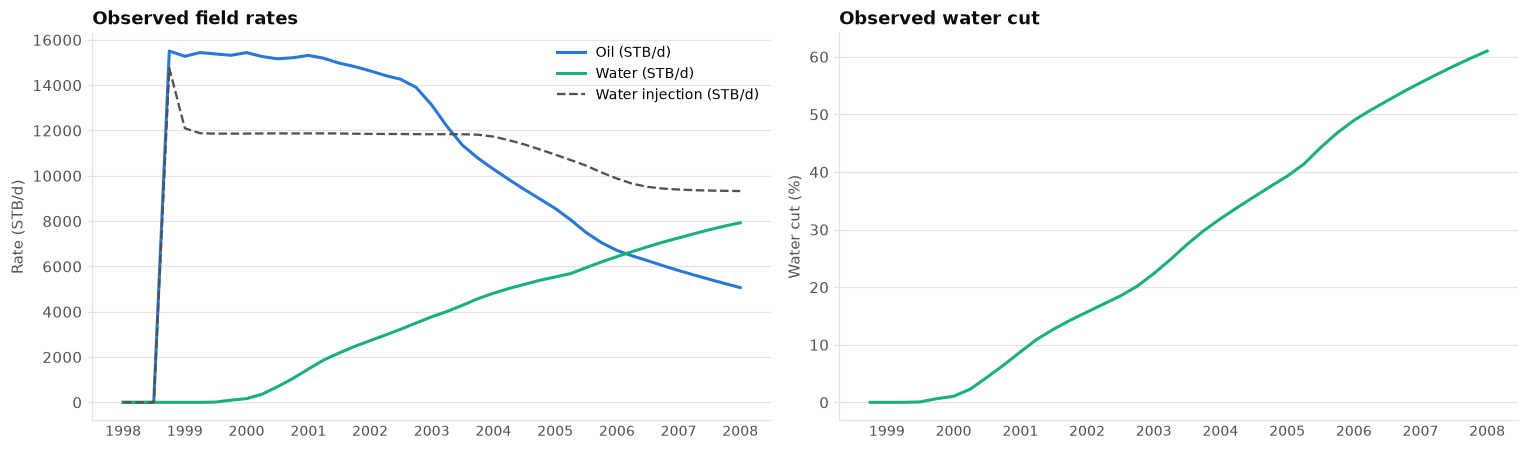

In [6]:
from src.plotting import INK_2, PHASE_COLORS, SLIDE_RC, clean_axes, plt, png_bytes

plt.rcParams.update(SLIDE_RC)
obs = io_load.load_observed(cfg)
show_table(obs.head(8).rename(columns={"oil": "Oil (STB/d)", "gas": "Gas (MSCF/d)", "water": "Water (STB/d)",
                                       "winj": "Water injection (STB/d)"}),
           title="Observed field rates: first 8 quarters", formats="{:,.2f}")
q_days = obs.index.to_series().diff().dt.days.dropna().astype(int)
print("Dates:", obs.index.min().date(), "->", obs.index.max().date(), "| rows:", len(obs),
      "| quarter lengths (days):", q_days.value_counts().sort_index().to_dict())

wc = obs["water"] / (obs["oil"] + obs["water"]).where(lambda s: s > 0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ax = axes[0]
ax.plot(obs.index, obs["oil"], color=PHASE_COLORS["oil"], lw=2, label="Oil (STB/d)")
ax.plot(obs.index, obs["water"], color=PHASE_COLORS["water"], lw=2, label="Water (STB/d)")
ax.plot(obs.index, obs["winj"], color=INK_2, lw=1.5, ls="--", label="Water injection (STB/d)")
ax.set_title("Observed field rates")
ax.set_ylabel("Rate (STB/d)")
ax.legend()
clean_axes(ax, "y")
ax = axes[1]
ax.plot(obs.index, 100 * wc, color=PHASE_COLORS["water"], lw=2)
ax.set_title("Observed water cut")
ax.set_ylabel("Water cut (%)")
clean_axes(ax, "y")
fig.tight_layout()
display(Image(data=png_bytes(fig)))
plt.close(fig)

In [7]:
prod = obs[obs["oil"] > 0]
start = prod.index[0]
peak_date, peak = obs["oil"].idxmax(), obs["oil"].max()
after = obs.loc[peak_date:]
plateau_end = after.index[after["oil"] < 0.95 * peak][0] if (after["oil"] < 0.95 * peak).any() else None
end_date, end_rate = obs.index[-1], obs["oil"].iloc[-1]
first_water = obs.index[obs["water"] > 0][0]
cross = obs.index[(obs["water"] > obs["oil"]) & (obs["oil"] > 0)]
gor = (obs["gas"] / obs["oil"])[obs["oil"] > 0]
inj = obs.loc[obs["winj"] > 0, "winj"]
n_fit = int((obs.index > pd.Timestamp(cfg["forecast"]["fit_window_start"])).sum())
show_md(f"""**Findings**
- {len(obs)} quarterly rows, {obs.index.min().date()} → {end_date.date()}; real quarter lengths
  ({", ".join(f"{d} days" for d in sorted(q_days.unique()))}) are used when rates are turned into volumes (F14).
- Production and water injection both start on **{start.date()}**; the first {int((obs.index < start).sum())} quarters are zero.
- Oil peaks at **{peak:,.0f} STB/d** ({peak_date.date()}){f", stays within 5% of the peak until it first falls below that level on **{plateau_end.date()}**" if plateau_end is not None else ""},
  then declines to **{end_rate:,.0f} STB/d** in {end_date.date()}, which is **{pct(1 - end_rate / peak)} below peak**.
- Water first appears on **{first_water.date()}**; water cut reaches **{pct(wc.iloc[-1])}** by {end_date.date()}
  {f"and water rate exceeds oil rate from **{cross[0].date()}**" if len(cross) else ""}.
- Injection runs from {inj.index[0].date()} at {inj.iloc[0]:,.0f} → {inj.iloc[-1]:,.0f} STB/d at the end of history.
- Observed gas–oil ratio: **{gor.min():.4f}–{gor.max():.4f} MSCF/STB** (essentially constant).

**Implications.**
- The field is a **waterflood in decline with rising water cut**: the forecast needs an oil decline model and a
  water model that follows the water–oil ratio, not a constant rate.
- The decline is already established in the last part of history, so forecast models are fitted on the periods
  after {pd.Timestamp(cfg["forecast"]["fit_window_start"]).date()} (**{n_fit} quarters**), not on the plateau.
- A constant gas–oil ratio means gas can be forecast as a fixed multiple of oil (checked on the simulations in §6).""")

**Findings**
- 41 quarterly rows, 1998-01-01 → 2008-01-01; real quarter lengths
  (90 days, 91 days, 92 days) are used when rates are turned into volumes (F14).
- Production and water injection both start on **1998-10-01**; the first 3 quarters are zero.
- Oil peaks at **15,508 STB/d** (1998-10-01), stays within 5% of the peak until it first falls below that level on **2002-01-01**,
  then declines to **5,067 STB/d** in 2008-01-01, which is **67.3% below peak**.
- Water first appears on **1999-04-01**; water cut reaches **61.0%** by 2008-01-01
  and water rate exceeds oil rate from **2006-04-01**.
- Injection runs from 1998-10-01 at 14,749 → 9,327 STB/d at the end of history.
- Observed gas–oil ratio: **0.3630–0.3636 MSCF/STB** (essentially constant).

**Implications.**
- The field is a **waterflood in decline with rising water cut**: the forecast needs an oil decline model and a
  water model that follows the water–oil ratio, not a constant rate.
- The decline is already established in the last part of history, so forecast models are fitted on the periods
  after 2004-01-01 (**16 quarters**), not on the plateau.
- A constant gas–oil ratio means gas can be forecast as a fixed multiple of oil (checked on the simulations in §6).

## 4. Simulated cumulative curves: form and reach

**Why.** The simulations are the training data of the proxy (SRQ4). Their time stamps decide how they must be
aligned with the observed dates (SRQ1); their last date decides how far the forecast has to extrapolate (SRQ5).
`RAMP_History` is a column in each sheet that is not a case; it is held apart and examined in §5.

In [8]:
curves, history = {}, {}
rows = []
for key, sheet in cfg["sheets"]["curves"].items():
    phase = key.removesuffix("_cum")                       # oil_cum -> oil
    curves[phase], history[phase] = io_load.load_curve_sheet(cfg, sheet)
    df = curves[phase]
    rows.append({"sheet": sheet, "timestamps": df.shape[0], "cases": df.shape[1],
                 "blank cells": pct(df.isna().mean().mean(), 2), "first date": df.index.min().date(),
                 "last date": df.index.max().date(), "median points per case": int(df.notna().sum().median())})
curve_info = pd.DataFrame(rows)
show_table(curve_info.rename(columns=str.capitalize), title="Simulated curve sheets in 02 Field Production.xlsx",
           align={"Blank cells": "right"})

Sheet,Timestamps,Cases,Blank cells,First date,Last date,Median points per case
Oil production cumulative,"11,096",100,98.45%,1998-01-01,2008-01-01,170
Gas production cumulative,"11,096",100,98.45%,1998-01-01,2008-01-01,170
Water production cumulative,"11,096",100,98.45%,1998-01-01,2008-01-01,170


In [9]:
last = max(curves[k].index.max() for k in curves)
show_md(f"""**Findings**
- Each sheet has **{curve_info['timestamps'].iloc[0]:,} irregular timestamps** for {curve_info['cases'].iloc[0]} cases, but a
  case reports only about **{curve_info['median points per case'].median():.0f}** of them, so {curve_info['blank cells'].iloc[0]} of cells are blank.
- Simulations run from {min(curves[k].index.min() for k in curves).date()} to **{last.date()}**, so there is
  **no simulated production after {last.date()}**.

**Implications.**
- Every case must be interpolated onto the {len(obs)} observed dates before it can be compared with the field (SRQ1,
  F20). Cumulatives are interpolated, not rates, because cumulative volume is conserved by linear interpolation.
- The 2008–2028 forecast cannot be learned from simulated futures; it has to **extrapolate** from the history
  (SRQ5), so it is validated by a temporal backtest (fit to 2004, forecast 2004–2008).""")

**Findings**
- Each sheet has **11,096 irregular timestamps** for 100 cases, but a
  case reports only about **170** of them, so 98.45% of cells are blank.
- Simulations run from 1998-01-01 to **2008-01-01**, so there is
  **no simulated production after 2008-01-01**.

**Implications.**
- Every case must be interpolated onto the 41 observed dates before it can be compared with the field (SRQ1,
  F20). Cumulatives are interpolated, not rates, because cumulative volume is conserved by linear interpolation.
- The 2008–2028 forecast cannot be learned from simulated futures; it has to **extrapolate** from the history
  (SRQ5), so it is validated by a temporal backtest (fit to 2004, forecast 2004–2008).

## 5. Date convention and `RAMP_History` (SRQ1 preview)

**Why.** A rate stamped on a date can mean "the rate for the quarter that *starts* here" or "...that *ends* here".
Choosing wrongly shifts the observed history by one quarter against the simulations and distorts every misfit.
Two conventions are integrated into cumulatives (F22) and compared with `RAMP_History`.

In [10]:
from src.s1_prepare import align_cumulative, observed_cumulative
from src.utils import PHASES

conv_rows = []
for conv in cfg["matching"]["date_conventions"]:
    oc = observed_cumulative(obs, conv)
    for k in PHASES:
        h = align_cumulative(history[k].to_frame("h"), obs.index)["h"].iloc[-1]
        conv_rows.append({"convention": conv, "phase": k,
                          "relative difference at 2008": abs(h - oc[k].iloc[-1]) / max(oc[k].iloc[-1], 1e-9)})
conv_tab = pd.DataFrame(conv_rows).pivot(index="convention", columns="phase", values="relative difference at 2008")
show_table(conv_tab[list(PHASES)].rename(columns=str.capitalize).rename_axis("Convention"),
           title="RAMP_History vs observed cumulative at 2008: relative difference", formats=sci(1))

Convention,Oil,Gas,Water
end,1.2e-02,1.2e-02,5.3e-02
start,2.5e-08,1.3e-16,2.5e-08


In [11]:
worst = conv_tab.max(axis=1)
best_conv = worst.idxmin()
show_md(f"""**Findings**
- Largest relative difference between `RAMP_History` and the observed cumulative at 2008:
  {", ".join(f"**{c}** {worst[c]:.1e}" for c in worst.index)}.
- Under the **"{best_conv}"** convention the two agree to {worst[best_conv]:.1e}. In other words, `RAMP_History` **is the
  observed history**, accumulated with the "{best_conv}" convention.

**Implication.** The observed rates are integrated with the "{best_conv}" convention. `02_pipeline` Step 1 repeats
this test formally on the history-match misfit (SRQ1) rather than relying on this check alone.""")

**Findings**
- Largest relative difference between `RAMP_History` and the observed cumulative at 2008:
  **end** 5.3e-02, **start** 2.5e-08.
- Under the **"start"** convention the two agree to 2.5e-08. In other words, `RAMP_History` **is the
  observed history**, accumulated with the "start" convention.

**Implication.** The observed rates are integrated with the "start" convention. `02_pipeline` Step 1 repeats
this test formally on the history-match misfit (SRQ1) rather than relying on this check alone.

## 6. Gas–oil ratio: is all produced gas solution gas?

**Why.** If gas leaves the oil at a fixed ratio (reservoir above bubble point), gas production is a constant
multiple of oil production (F13) and does not need its own forecasting model.

In [12]:
sim = {k: align_cumulative(curves[k], obs.index) for k in PHASES}
rs = (sim["gas"].iloc[-1] - sim["gas"].iloc[0]) / (sim["oil"].iloc[-1] - sim["oil"].iloc[0])
rs_ref, tol = cfg["gas"]["rs_expected"], cfg["gas"]["rs_tolerance"]
print(f"Rs over 1998-2008 across {rs.size} cases: min {rs.min():.4f}, median {rs.median():.4f}, max {rs.max():.4f} MSCF/STB")

Rs over 1998-2008 across 100 cases: min 0.3632, median 0.3632, max 0.3633 MSCF/STB


In [13]:
n_off = int(((rs - rs_ref).abs() / rs_ref > tol).sum())
show_md(f"""**Findings**
- Produced gas / produced oil over 1998–2008 is **{rs.min():.4f}–{rs.max():.4f} MSCF/STB** across all {rs.size} cases
  (spread {pct((rs.max() - rs.min()) / rs.median(), 2)} of the median); {n_off} cases differ from {rs_ref} by more than {pct(tol, 0)}.
- The observed field ratio (§3) is the same: {gor.min():.4f}–{gor.max():.4f}.

**Implication.** Gas is treated as **solution gas**: forecast gas = Rs × forecast oil, with Rs measured on each
history's own fit window (F13). Gas therefore carries no extra unknowns, and gas results mirror oil results.""")

**Findings**
- Produced gas / produced oil over 1998–2008 is **0.3632–0.3633 MSCF/STB** across all 100 cases
  (spread 0.04% of the median); 0 cases differ from 0.3633 by more than 2%.
- The observed field ratio (§3) is the same: 0.3630–0.3636.

**Implication.** Gas is treated as **solution gas**: forecast gas = Rs × forecast oil, with Rs measured on each
history's own fit window (F13). Gas therefore carries no extra unknowns, and gas results mirror oil results.

## 7. Which parameter drives the 1998–2008 production?

**Why.** History matching can only pin down parameters that change the history. Spearman rank correlation between
each parameter and each case's 2008 cumulatives gives a first, model-free view of which parameters are
*identifiable* from the history (SRQ2) and which drive production (SRQ3).

In [14]:
end = pd.DataFrame({f"cum_{k}_2008": sim[k].iloc[-1] for k in PHASES})
rho = params.join(end).corr(method="spearman").loc[names, end.columns]
show_table(rho.rename(columns=lambda c: c.removeprefix("cum_").replace("_", " ").capitalize())
           .rename_axis("Parameter"),
           title="Spearman ρ between each parameter and cumulative production at 2008 (100 cases)", formats="{:+.3f}")

Parameter,Oil 2008,Gas 2008,Water 2008
Fault Transmissibility,+0.139,+0.139,-0.141
Porosity Multiplier,+0.993,+0.992,-0.995
Permeability Multiplier,+0.089,+0.091,-0.008
Aquifer Pore Volume,-0.080,-0.080,+0.144


In [15]:
top = rho.abs().idxmax()
lines = []
for col in rho.columns:
    others = rho[col].drop(top[col]).abs()
    lines.append(f"- {col.replace('cum_', '').replace('_2008', '')}: **{top[col]}** ρ = {rho.loc[top[col], col]:+.3f}; "
                 f"next strongest |ρ| = {others.max():.3f} ({others.idxmax()})")
dominant = top.nunique() == 1
show_md("**Findings**\n" + "\n".join(lines) + f"""

**Implications.**
- {"One parameter, **" + top.iloc[0] + "**, controls the history of every phase" if dominant else "Different parameters control different phases"};
  it should be **well identified** by history matching.
- Parameters with weak correlation leave little trace in 1998–2008 production, so several combinations of them can
  match equally well. **Non-uniqueness is expected** (tested in SRQ2), and their effect may only appear later
  (tested on the 2028 forecast in SRQ3).
- A proxy that compresses all phases together would be dominated by the strong parameter; the proxy therefore uses
  a **separate PCA for each phase** (F29) so that the weaker effects are not discarded.""")

**Findings**
- oil: **Porosity Multiplier** ρ = +0.993; next strongest |ρ| = 0.139 (Fault Transmissibility)
- gas: **Porosity Multiplier** ρ = +0.992; next strongest |ρ| = 0.139 (Fault Transmissibility)
- water: **Porosity Multiplier** ρ = -0.995; next strongest |ρ| = 0.144 (Aquifer Pore Volume)

**Implications.**
- One parameter, **Porosity Multiplier**, controls the history of every phase;
  it should be **well identified** by history matching.
- Parameters with weak correlation leave little trace in 1998–2008 production, so several combinations of them can
  match equally well. **Non-uniqueness is expected** (tested in SRQ2), and their effect may only appear later
  (tested on the 2028 forecast in SRQ3).
- A proxy that compresses all phases together would be dominated by the strong parameter; the proxy therefore uses
  a **separate PCA for each phase** (F29) so that the weaker effects are not discarded.

## 8. Do the 100 simulations bracket the observed field?

**Why.** History matching searches *between* the simulated cases. If the observed history lay outside the range
of all 100 simulations, no parameter set in the design space could match it and the proxy would have to
extrapolate. Grey lines are the 100 cases; black points are the observed cumulatives (convention found in §5).

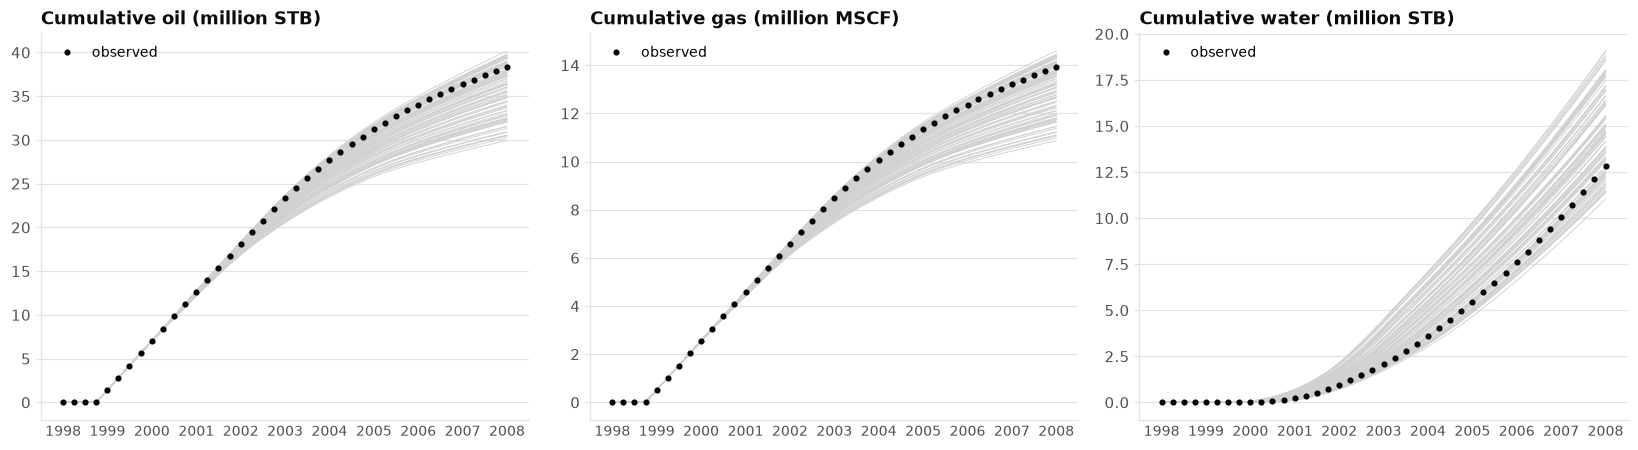

In [16]:
oc = observed_cumulative(obs, best_conv)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
UNITS = {"oil": "STB", "gas": "MSCF", "water": "STB"}
inside, pctl, diverge = {}, {}, {}
for ax, k in zip(axes, PHASES):
    lo, hi = sim[k].min(axis=1), sim[k].max(axis=1)
    live = hi > 0
    tol = 1e-6 * hi.abs().clip(lower=1.0)                 # rounding-level tolerance
    inside[k] = float(((oc[k] >= lo - tol) & (oc[k] <= hi + tol))[live].mean())
    spread = ((hi - lo) / hi.where(live))[live]
    diverge[k] = spread.index[spread > 1e-3][0] if (spread > 1e-3).any() else None   # cases differ by > 0.1%
    pctl[k] = float((sim[k].iloc[-1] < oc[k].iloc[-1]).mean())
    ax.plot(sim[k].index, sim[k].to_numpy() / 1e6, color="0.82", lw=0.6)
    ax.plot(oc.index, oc[k] / 1e6, "o", color="black", ms=3, label="observed")
    ax.set_title(f"Cumulative {k} (million {UNITS[k]})")
    ax.legend(loc="upper left")
    clean_axes(ax, "y")
fig.tight_layout()
display(Image(data=png_bytes(fig)))
plt.close(fig)

In [17]:
show_md(f"""**Findings**
- Share of producing dates on which the observed cumulative lies inside the min–max range of the 100 cases:
  {", ".join(f"{k} **{pct(inside[k], 0)}**" for k in PHASES)}.
- Position of the observed 2008 cumulative among the 100 cases (share of cases below it):
  {", ".join(f"{k} **{pct(pctl[k], 0)}**" for k in PHASES)}.
- The 100 cases first differ by more than 0.1% on: {", ".join(f"{k} **{diverge[k].date()}**" for k in PHASES if diverge[k] is not None)}.
  Before that, every case produces the same volumes (the wells deliver a set rate), so **those dates carry no
  information about the parameters**; what distinguishes the cases is the later history.

**Implication.** {"The observed field lies inside the simulated range for every phase, so history matching is an "
"interpolation problem within the design space." if min(inside.values()) == 1 else
"The observed field leaves the simulated range for part of the history; matched parameters may sit at the edge of "
"the design space, and that edge has to be reported as a limitation."} Because the early quarters are identical in
every case, the misfit is driven by the later history, where the cases separate.""")

**Findings**
- Share of producing dates on which the observed cumulative lies inside the min–max range of the 100 cases:
  oil **100%**, gas **100%**, water **100%**.
- Position of the observed 2008 cumulative among the 100 cases (share of cases below it):
  oil **72%**, gas **72%**, water **29%**.
- The 100 cases first differ by more than 0.1% on: oil **1999-10-01**, gas **1999-10-01**, water **1999-04-01**.
  Before that, every case produces the same volumes (the wells deliver a set rate), so **those dates carry no
  information about the parameters**; what distinguishes the cases is the later history.

**Implication.** The observed field lies inside the simulated range for every phase, so history matching is an interpolation problem within the design space. Because the early quarters are identical in
every case, the misfit is driven by the later history, where the cases separate.

## 9. Grid workbooks: do they hold information beyond the 4 parameters? 

**Why.** The six grid workbooks (1.66 GB; their names follow the split: *Train Cases 1–4*, *Validation Cases*,
*Test Cases*) describe every case cell by cell: 90,365 cells × 29 properties. If a case's grid can be rebuilt
exactly as **the first case's grid × that case's multipliers**, the grids contain nothing the 4 parameters do not, and
a model gains nothing by reading them (SRQ4). This section tests that on every case it reads.

**Method.**
1. The first case found is the **base**; comparing it with the second case locates three cell groups: the
   permeability region (PERMX changes), the aquifer cells (pore volume changes beyond porosity) and the oil zone
   (initial oil saturation above 0).
2. Each case is predicted column by column from the base: porosity × porosity ratio (F2); pore volume × porosity
   ratio, and × aquifer ratio in aquifer cells; PERMX/PERMY × permeability ratio in the region (F9); every other column
   unchanged. The largest relative error per column is recorded (export rounding gives about 1e-5).
3. Transmissibilities TRANX/TRANY must change only between 1 and the permeability ratio. Where the fault ratio lies
   outside that range, any cell scaled by it would reveal the fault multiplier.
4. HCPV = Σ pore volume × oil saturation (F3a) is compared with `config.yaml` → base HCPV × porosity multiplier.

**Scope.** `GRID_SCOPE = "sample"` reads the first 2 cases of every grid file present ;
`"all"` reads every case; `"off"` skips the section.

In [18]:
from openpyxl import load_workbook

from src import grid
from src.config import find_raw_file
from src.utils import norm_case

GRID_SCOPE = "sample"            # "sample" | "all" | "off"

present = []
for name in cfg["files"]["grid"]:
    try:
        present.append(find_raw_file(cfg, name))
    except FileNotFoundError:
        print(f"{name}: not present")
grid_rows, base, masks, layout = [], None, None, None
if GRID_SCOPE != "off" and present:
    nv = cfg["grid"]["null_value"]
    for path in present:
        wb = load_workbook(path, read_only=True)
        sheet_names = wb.sheetnames
        wb.close()
        todo = sheet_names if GRID_SCOPE == "all" else sheet_names[:2]
        print(f"{path.name}: {len(sheet_names)} case sheets, checking {len(todo)}")
        for sh in todo:
            case, cid = grid.read_grid_sheet(path, sh, nv), norm_case(sh)
            if base is None:
                base, base_id = case, cid
                n_cells, n_active = len(case[1]), int(grid.active_mask(*case).sum())
                print(f"  base = {cid}: {n_cells} cells (config {cfg['grid']['cells_per_case']}), "
                      f"{n_active} active (config {cfg['grid']['active_cells_per_case']})")
                continue
            r = grid.ratios(params.loc[base_id], params.loc[cid])
            if masks is None:
                masks = grid.region_masks(base, case, r["poro"])
                layout = grid.layout_summary(base, masks)
            res = grid.check_case(base, case, masks, r)
            res["hcpv_rel_err"] = abs(res["hcpv_rb"] / (cfg["grid"]["hcpv_base_rb"] * params.loc[cid, "Porosity Multiplier"]) - 1)
            grid_rows.append({"file": path.name, "case": cid, "split": split.get(cid), **res})
grid_tab = pd.DataFrame(grid_rows)
if len(grid_tab):
    grid_cols = {"file": "File", "case": "Case", "split": "Split", "same_active_cells": "Same cells",
                 "PORO_max_rel_err": "PORO", "PORV_max_rel_err": "PORV", "PERMX_max_rel_err": "PERMX",
                 "PERMY_max_rel_err": "PERMY", "unchanged_cols_max_abs_diff": "Others", "tran_cells_unexplained": "TRAN",
                 "fault_testable": "Fault testable", "fault_scaled_cells": "Fault cells", "hcpv_rel_err": "HCPV"}
    show_table(grid_tab[list(grid_cols)].rename(columns=grid_cols),
               title=f"Each case rebuilt as the base grid ({base_id}) × its multipliers: largest relative error",
               formats={**{c: sci(1) for c in ("PORO", "PORV", "PERMX", "PERMY", "HCPV")},
                        "Others": "{:g}", "Fault cells": "{:.0f}"},
               note="Same cells: same active cells as the base. PORO, PORV, PERMX, PERMY: largest relative error of the "
                    "rebuilt column (export rounding gives about 1e-5). Others: largest absolute difference in the "
                    f"{len(base[0]) - len(grid.SCALED_COLUMNS)} other columns. TRAN: TRANX/TRANY cells not explained by the permeability multiplier. Fault cells: "
                    "cells scaled by the fault ratio (n/a where it cannot be told apart from the permeability ratio). "
                    "HCPV: relative difference from base HCPV × porosity multiplier in config.yaml.")
else:
    print("No grid case checked (no file present or GRID_SCOPE = 'off').")

03 Train Cases 1.xlsx: 20 case sheets, checking 2
  base = CASE 1: 90365 cells (config 90365), 42512 active (config 42512)
04 Train Cases 2.xlsx: 20 case sheets, checking 2
05 Train Cases 3.xlsx: 20 case sheets, checking 2
06 Train Cases 4.xlsx: 10 case sheets, checking 2
07  Validation Cases.xlsx: 15 case sheets, checking 2
08 Test Cases.xlsx: 15 case sheets, checking 2


File,Case,Split,Same cells,PORO,PORV,PERMX,PERMY,Others,TRAN,Fault testable,Fault cells,HCPV
03 Train Cases 1.xlsx,CASE 2,train,Yes,2.1e-05,2.1e-07,3.3e-06,3.3e-06,0,0,No,n/a,7.4e-10
04 Train Cases 2.xlsx,CASE 21,train,Yes,2.2e-05,1.9e-07,3.4e-06,3.4e-06,0,0,Yes,0,7.6e-10
04 Train Cases 2.xlsx,CASE 22,train,Yes,2.3e-05,2.7e-07,2.0e-06,2.0e-06,0,0,Yes,0,9.4e-10
05 Train Cases 3.xlsx,CASE 41,train,Yes,2.5e-05,2.1e-07,1.2e-06,1.2e-06,0,0,Yes,0,9.7e-10
05 Train Cases 3.xlsx,CASE 42,train,Yes,1.9e-05,2.0e-07,3.9e-06,3.9e-06,0,0,No,n/a,4.5e-10
06 Train Cases 4.xlsx,CASE 61,train,Yes,2.1e-05,1.9e-07,2.1e-06,2.1e-06,0,0,Yes,0,2.7e-10
06 Train Cases 4.xlsx,CASE 62,train,Yes,2.1e-05,1.9e-07,3.7e-06,3.7e-06,0,0,No,n/a,6.6e-10
07 Validation Cases.xlsx,CASE 71,validation,Yes,1.9e-05,1.9e-07,1.3e-06,1.3e-06,0,0,Yes,0,1.3e-09
07 Validation Cases.xlsx,CASE 72,validation,Yes,2.0e-05,2.1e-07,3.3e-06,3.3e-06,0,0,Yes,0,9.6e-10
08 Test Cases.xlsx,CASE 86,test,Yes,2.4e-05,1.8e-07,3.5e-06,3.5e-06,0,0,Yes,0,8.8e-10


In [19]:
if grid_tab.empty:
    grid_ok = None
    show_md("**Findings.** No grid case was checked, so the conclusion recorded in `research/02_data_facts.md` §6 stands.")
else:
    err_cols = ["PORO_max_rel_err", "PORV_max_rel_err", "PERMX_max_rel_err", "PERMY_max_rel_err"]
    max_err = float(grid_tab[err_cols].max().max())
    testable = grid_tab[grid_tab["fault_testable"]]
    fault_seen = int(testable["fault_scaled_cells"].sum()) if len(testable) else 0
    grid_ok = bool(grid_tab["same_active_cells"].all() and max_err < 1e-4
                   and grid_tab["unchanged_cols_max_abs_diff"].max() == 0
                   and grid_tab["tran_cells_unexplained"].sum() == 0)
    by_split = grid_tab["split"].value_counts().to_dict()
    show_md(f"""**Findings** ({len(grid_tab) + 1} cases read, base {base_id}; checked by split: {by_split})
- Same active cells in every case: **{bool(grid_tab['same_active_cells'].all())}**.
- Largest error when each case is rebuilt as base × its multipliers: **{max_err:.1e}** (porosity, pore volume,
  PERMX, PERMY). That is just the rounding in the exported numbers.
- The other {len(base[0]) - 6} columns (coordinates, PERMZ, NTG, TRANZ, regions, saturation end-points, initial
  pressure and saturations): largest difference **{grid_tab['unchanged_cols_max_abs_diff'].max():g}**, i.e. identical in every case.
- TRANX/TRANY cells not explained by the permeability multiplier: **{int(grid_tab['tran_cells_unexplained'].sum())}**.
- **Fault multiplier:** in the {len(testable)} cases where it could be told apart from permeability, **{fault_seen} cells**
  change by the fault ratio, so it {"is not stored in the grid files at all (the simulator applies it on fault faces)" if fault_seen == 0 else "does appear in the grid"}.
- HCPV vs `config.yaml` (base HCPV × porosity multiplier): largest difference {grid_tab['hcpv_rel_err'].max():.1e}.

**Implication.** {"Every grid checked is the base grid × the porosity, permeability and aquifer multipliers, and the "
"fault multiplier is absent. The grid files therefore hold **no information beyond the 4 parameters** (less, "
"in fact, since the fault multiplier is missing), so they are not model inputs. The proxy already reproduces the simulator from the 4 parameters alone "
"(Step 2), which bounds what any grid feature could add." if grid_ok else
"Some grids differ from base × multipliers, so grid-derived features should be tested as extra proxy inputs."}
{"" if GRID_SCOPE == "all" else "Set `GRID_SCOPE = \"all\"` and re-run this cell once to confirm every case."}""")

**Findings** (12 cases read, base CASE 1; checked by split: {'train': 7, 'validation': 2, 'test': 2})
- Same active cells in every case: **True**.
- Largest error when each case is rebuilt as base × its multipliers: **2.5e-05** (porosity, pore volume,
  PERMX, PERMY). That is just the rounding in the exported numbers.
- The other 23 columns (coordinates, PERMZ, NTG, TRANZ, regions, saturation end-points, initial
  pressure and saturations): largest difference **0**, i.e. identical in every case.
- TRANX/TRANY cells not explained by the permeability multiplier: **0**.
- **Fault multiplier:** in the 8 cases where it could be told apart from permeability, **0 cells**
  change by the fault ratio, so it is not stored in the grid files at all (the simulator applies it on fault faces).
- HCPV vs `config.yaml` (base HCPV × porosity multiplier): largest difference 1.4e-09.

**Implication.** Every grid checked is the base grid × the porosity, permeability and aquifer multipliers, and the fault multiplier is absent. The grid files therefore hold **no information beyond the 4 parameters** (less, in fact, since the fault multiplier is missing), so they are not model inputs. The proxy already reproduces the simulator from the 4 parameters alone (Step 2), which bounds what any grid feature could add.
Set `GRID_SCOPE = "all"` and re-run this cell once to confirm every case.

### Where things sit in the reservoir

The grid cannot add information, but it explains the physics behind the results: where the oil is, where the
aquifer is, and which cells the permeability multiplier changes.

In [20]:
if layout is None:
    show_md("No grid case was checked, so the layout is not available.")
else:
    lay = pd.DataFrame(layout).T
    lay_show = pd.DataFrame({
        "Cells": lay["cells"], "Pore-volume share": lay["pore_volume_share"].map(pct),
        "Z min": lay.get("z_min"), "Z max": lay.get("z_max"), "I range": lay.get("i_range"),
        "J range": lay.get("j_range"), "K range": lay.get("k_range"), "Cells in oil zone": lay.get("in_oil_zone"),
    }).rename(index={"oil_zone": "Oil zone", "aquifer": "Aquifer cells", "perm_region": "Permeability region"})
    show_table(lay_show.rename_axis("Cell group"), title="Where the oil zone, aquifer and permeability region sit",
               formats={"Z min": "{:,.0f}", "Z max": "{:,.0f}"},
               align={c: "right" for c in ("Pore-volume share", "I range", "J range", "K range")},
               note="Base grid. Z values as exported (likely ft, negative downward). "
                    "Pore-volume share is the share of all active cells' pore volume.")
    oz, aqf, pr = layout["oil_zone"], layout["aquifer"], layout["perm_region"]
    deeper = aqf.get("z_max", 0) < oz.get("z_min", 0)
    show_md(f"""**Findings**
- **Oil zone:** {oz['cells']:,} cells holding {pct(oz['pore_volume_share'])} of the pore volume.
- **Aquifer cells:** {aqf['cells']:,} cells, none in the oil zone, holding **{pct(aqf['pore_volume_share'])}** of the pore
  volume. These are large cells in grid columns I {aqf['i_range'][0]}–{aqf['i_range'][1]}{", deeper than the oil zone" if deeper else ""}.
- **Permeability region:** {pr['cells']:,} cells in layers K {pr['k_range'][0]}–{pr['k_range'][1]}; {pr['in_oil_zone']:,} of them
  in the oil zone and {pr['cells'] - pr['in_oil_zone']:,} below it.

**Implication.** The aquifer sits at the edge of the grid{", below the oil" if deeper else ""}, so its support reaches the
wells late. This fits with the aquifer's influence on water growing between 2008 and 2028 (Step 6). The permeability
multiplier acts mostly in the lower, water-bearing layers, so it changes water movement more than oil (Step 6).
Depths are the grid's Z values, as exported.""")

Cell group,Cells,Pore-volume share,Z min,Z max,I range,J range,K range,Cells in oil zone
Oil zone,"11,004",4.2%,"-8,100","-7,572",4–43,5–53,1–31,n/a
Aquifer cells,"2,286",83.5%,"-9,153","-8,311",51–53,1–55,1–31,0
Permeability region,"11,575",2.8%,"-8,911","-7,700",1–48,1–55,13–31,"3,759"


**Findings**
- **Oil zone:** 11,004 cells holding 4.2% of the pore volume.
- **Aquifer cells:** 2,286 cells, none in the oil zone, holding **83.5%** of the pore
  volume. These are large cells in grid columns I 51–53, deeper than the oil zone.
- **Permeability region:** 11,575 cells in layers K 13–31; 3,759 of them
  in the oil zone and 7,816 below it.

**Implication.** The aquifer sits at the edge of the grid, below the oil, so its support reaches the
wells late. This fits with the aquifer's influence on water growing between 2008 and 2028 (Step 6). The permeability
multiplier acts mostly in the lower, water-bearing layers, so it changes water movement more than oil (Step 6).
Depths are the grid's Z values, as exported.

## 10. Summary: what the EDA decides for the method

The table is generated from the findings above; each row names the step of `02_pipeline.ipynb` that uses it.

In [21]:
summary = pd.DataFrame([
    {"Finding": f"No pressure data; {len(sheets)} sheets" if not has_pressure else "Pressure data available",
     "Decision": "Match on oil, gas and water volumes only", "Used in": "Step 3 (SRQ2)"},
    {"Finding": f"Inputs independent (largest correlation {off.max():.2f}); permeability spans {ratio['Permeability Multiplier']:.0f}×",
     "Decision": "ln(permeability), min–max scaling; Sobol indices interpretable", "Used in": "Steps 1, 6"},
    {"Finding": f"Oil {pct(1 - end_rate / peak, 0)} below peak and water cut {pct(wc.iloc[-1], 0)} by 2008",
     "Decision": "Oil decline + water–oil-ratio forecast, fitted on the late history", "Used in": "Step 4 (SRQ5)"},
    {"Finding": f"Irregular simulator time steps; no simulated data after {last.date()}",
     "Decision": "Interpolate cumulatives onto observed dates; validate forecasts by backtest", "Used in": "Steps 1, 4"},
    {"Finding": f"RAMP_History = observed history under the '{best_conv}' convention",
     "Decision": f"Integrate observed rates with the '{best_conv}' convention (formal test in Step 1)", "Used in": "Step 1 (SRQ1)"},
    {"Finding": f"Gas–oil ratio constant ({rs.min():.4f}–{rs.max():.4f} MSCF/STB)",
     "Decision": "Gas = Rs × oil", "Used in": "Step 4"},
    {"Finding": f"{top.iloc[0]} dominates the history" if dominant else "Different drivers per phase",
     "Decision": "Per-phase PCA proxy; expect non-uniqueness for the other parameters", "Used in": "Steps 2, 3, 6"},
    {"Finding": f"Observed inside the simulated range on {pct(min(inside.values()), 0)} of dates (worst phase); "
                f"cases identical until {min(d for d in diverge.values() if d is not None).date()}",
     "Decision": "History matching within the design space", "Used in": "Step 3"},
    {"Finding": (f"Grids = base grid × 3 multipliers ({len(grid_tab) + 1} cases); fault multiplier absent"
                 if grid_ok else "Grid check not run" if grid_ok is None else "Grids differ from base × multipliers"),
     "Decision": "Grids not used as inputs; used for HCPV and reservoir layout", "Used in": "Steps 2, 5, 6"},
])
show_table(summary, title="Summary: what the EDA decides for the method")

Finding,Decision,Used in
No pressure data; 8 sheets,"Match on oil, gas and water volumes only",Step 3 (SRQ2)
Inputs independent (largest correlation 0.17); permeability spans 19×,"ln(permeability), min–max scaling; Sobol indices interpretable","Steps 1, 6"
Oil 67% below peak and water cut 61% by 2008,"Oil decline + water–oil-ratio forecast, fitted on the late history",Step 4 (SRQ5)
Irregular simulator time steps; no simulated data after 2008-01-01,Interpolate cumulatives onto observed dates; validate forecasts by backtest,"Steps 1, 4"
RAMP_History = observed history under the 'start' convention,Integrate observed rates with the 'start' convention (formal test in Step 1),Step 1 (SRQ1)
Gas–oil ratio constant (0.3632–0.3633 MSCF/STB),Gas = Rs × oil,Step 4
Porosity Multiplier dominates the history,Per-phase PCA proxy; expect non-uniqueness for the other parameters,"Steps 2, 3, 6"
Observed inside the simulated range on 100% of dates (worst phase); cases identical until 1999-04-01,History matching within the design space,Step 3
Grids = base grid × 3 multipliers (12 cases); fault multiplier absent,Grids not used as inputs; used for HCPV and reservoir layout,"Steps 2, 5, 6"
